Image successfully saved as 'algorithm_visualisation.png'


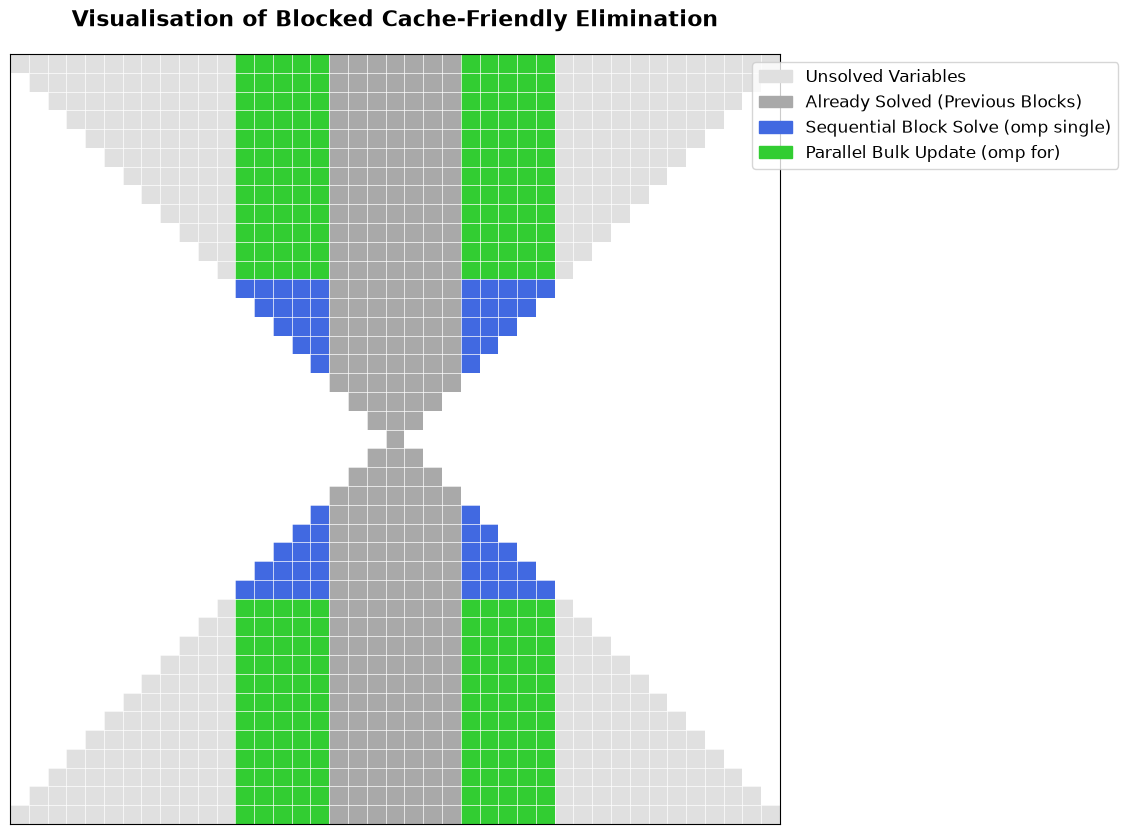

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

def generate_algorithm_visualization():
    n = 20
    N = 2 * n + 1
    matrix = np.zeros((N, N))

    # Define a sample block step
    bs = 4
    be = 8

    # Fill matrix based strictly on q2.cpp's loop bounds
    for row in range(N):
        # The hourglass/bowtie shape from InitializeInput
        left = min(row, N - 1 - row)
        right = max(row, N - 1 - row)
        
        for col in range(left, right + 1):
            # 1. Default: Unsolved elements
            matrix[row, col] = 1

            # 2. Already solved columns (variables x[n-bs+1] to x[n+bs-1])
            if n - bs < col < n + bs:
                matrix[row, col] = 2

            # Determine row/col regions for the current block
            is_block_col = (n - be <= col <= n - bs) or (n + bs <= col <= n + be)
            is_block_row = (n - be <= row <= n - bs) or (n + bs <= row <= n + be)
            is_outer_row = (row < n - be) or (row > n + be)

            # 3. Sequential solve uses intersections of block rows and block columns
            if is_block_col and is_block_row:
                matrix[row, col] = 3
                
            # 4. Parallel update uses block columns applied to outer unsolved rows
            elif is_block_col and is_outer_row:
                matrix[row, col] = 4

    # Custom Colors: 
    # 0=White (0s in matrix), 1=Light Gray (Unsolved), 2=Dark Gray (Solved), 
    # 3=Blue (Sequential), 4=Green (Parallel)
    cmap = ListedColormap(['white', '#E0E0E0', '#A9A9A9', '#4169E1', '#32CD32'])

    fig, ax = plt.subplots(figsize=(10, 10))
    cax = ax.imshow(matrix, cmap=cmap, interpolation='nearest')

    # Add gridlines to show individual cells
    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle='-', linewidth=0.5)
    ax.tick_params(which="minor", size=0)
    ax.set_xticks([])
    ax.set_yticks([])

    # Legend handles mapping to the colors
    handles = [
        mpatches.Patch(color='#E0E0E0', label='Unsolved Variables'),
        mpatches.Patch(color='#A9A9A9', label='Already Solved (Previous Blocks)'),
        mpatches.Patch(color='#4169E1', label='Sequential Block Solve (omp single)'),
        mpatches.Patch(color='#32CD32', label='Parallel Bulk Update (omp for)')
    ]
    ax.legend(handles=handles, loc='upper right', bbox_to_anchor=(1.45, 1), fontsize=12)

    plt.title("Visualisation of Blocked Cache-Friendly Elimination", fontsize=16, fontweight='bold', pad=20)
    
    # Save and display
    plt.savefig('algorithm_visualisation.png', dpi=300, bbox_inches='tight')
    print("Image successfully saved as 'algorithm_visualisation.png'")
    plt.show()

if __name__ == '__main__':
    generate_algorithm_visualization()

In [6]:
# Uncomment if matplotlib is not installed:
# %pip install matplotlib

%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "serif", "font.size": 11,
    "axes.labelsize": 12, "legend.fontsize": 10,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

In [7]:
THREADS = [1, 2, 4, 8, 16]

TIMES_US = {
    512: [374.600, 402.800, 411.600, 439.600, 504.600],
    1024: [2350.000, 1749.600, 1216.800, 1125.200, 1071.600],
    2048: [12959.000, 7776.600, 4602.000, 3536.000, 3482.200],
    4096: [50073.600, 25471.600, 16081.600, 11734.600, 11115.600],
    8192: [217602.200, 118109.400, 67791.600, 45992.600, 40873.200],
}

COLORS = ["#d62728", "#1f77b4", "#e68a00", "#2ca02c", "#9467bd"]

In [8]:
def make_plot(output_dir, stem, ylabel, speedup=False, log_time=False):
    fig, ax = plt.subplots(figsize=(7.2, 4.8), constrained_layout=True)
    for (n, times), color in zip(TIMES_US.items(), COLORS):
        values = [times[0] / value for value in times] if speedup else times
        exponent = n.bit_length() - 1
        ax.plot(
            THREADS, values, color=color, marker="s", markersize=5,
            linewidth=1.7, label=rf"$n = 2^{{{exponent}}}$",
        )

    # Keep the proportional thread spacing used in the reference image.
    ax.set_xticks(THREADS)
    ax.set_xlabel("Number of threads")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.45)
    ax.set_axisbelow(True)

    if speedup:
        ax.axhline(1, color="0.5", linestyle="--", linewidth=0.9, zorder=0)
        ax.set_ylim(bottom=0)
        ax.legend(loc="upper left", frameon=True)
    else:
        if log_time:
            ax.set_yscale("log")
        else:
            ax.set_ylim(bottom=0)
            ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0),
                                useMathText=True)
        ax.legend(loc="upper right", frameon=True)

    # PDF keeps labels and lines sharp when scaled in a LaTeX report.
    for extension in ("png", "pdf"):
        path = output_dir / f"{stem}.{extension}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print(f"Saved {path}")
    plt.show()
    plt.close(fig)

Saved outputs\q2_time_vs_threads.png
Saved outputs\q2_time_vs_threads.pdf


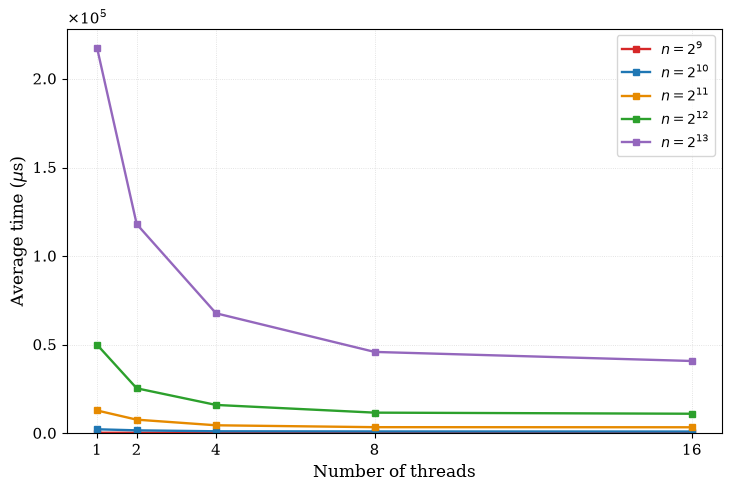

In [9]:
LOG_TIME = False
make_plot(OUTPUT_DIR, "q2_time_vs_threads",
          r"Average time ($\mu$s)", log_time=LOG_TIME)

Saved outputs\q2_speedup_vs_threads.png
Saved outputs\q2_speedup_vs_threads.pdf


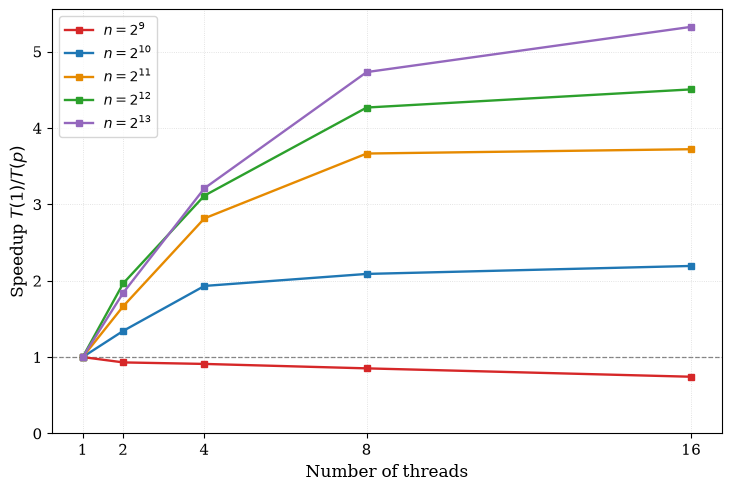

In [10]:
make_plot(OUTPUT_DIR, "q2_speedup_vs_threads",
          r"Speedup $T(1)/T(p)$", speedup=True)